In [1]:
import gensim
import logging
import multiprocessing
import os
import re
import sys
from gensim.models import word2vec
import numpy as np
from time import time

import matplotlib.pyplot as plt
import pandas as pd


## 一、默认程序及结果

### 1.1 默认程序

In [30]:
logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.INFO)

if __name__ == '__main__':

    data_path = 'text8'
    t = time()

    # loading dataset
    sents = word2vec.Text8Corpus('text8')

    # training word2vec
    model = gensim.models.Word2Vec(sents,   
                                   vector_size=200, # shaw
                                   window=10,
                                   min_count=10,
                                   workers=multiprocessing.cpu_count())

    # saving to file
    model.save("word2vec_gensim")
    model.wv.save_word2vec_format("word2vec_org",
                                  "vocabulary",
                                  binary=False)

    print ("Total time: %d s" % (time() - t))
    
    # testing on wordsim353
    sims = []
    with open('wordsim353/combined.csv') as f:
        for line in f.readlines()[1:]:
            l = line.strip().split(',')
            # if l[0] in model.wv.vocab and l[1] in model.wv.vocab: # 过滤掉不在词表内的词
            if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                sims.append(model.wv.similarity(l[0], l[1])) # 模型打分
    
    np.save('score.npy', np.array(sims))

Total time: 39 s


### 1.2 默认结果

In [31]:
# coding=utf-8
# This is a sample Python script.

import sys
# 用于打印JSON编码的评分结果
import json
import numpy as np
from scipy.stats import spearmanr

In [32]:
def eval(score_file):
    sims = np.load(score_file)
    score = np.load('ground_truth.npy')
    # 计算Spearman相关系数
    spcor = spearmanr(score, sims)[0]
    # 以下返回值主要用于aistudio的比赛，但是本次实验不设置比赛，大家只用看score的值
    return {
        "score": spcor,              #替换value为最终评测分数
        "errorMsg": "success",      #错误提示信息，仅在code值为非0时打印
        "code": 0,                  #code值为0打印score，非0打印errorMsg
        "data": [
            {
                "score": spcor 
            }
        ]
    }

if __name__ == '__main__':
    # 打印格式必须为JSON编码的字符串
    print(json.dumps(eval('score.npy')))

{"score": 0.6944340487743506, "errorMsg": "success", "code": 0, "data": [{"score": 0.6944340487743506}]}


## 二、参数对模型的影响

In [2]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'vector_size', 'window', 'min_count', 'train_time', 'vocab_len', 'score'])

## 2.1 vector_size 对模型的影响

In [5]:

from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    window = 10
    min_count = 10
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for vector_size in tqdm(range(50, 401, 25), desc = 'vector_size', colour='red'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        training_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        exec_result.loc[exec_result.shape[0]] = ['word2vec', epoch, vector_size, window, min_count, training_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_org_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


vector_size:   0%|          | 0/15 [00:00<?, ?it/s]

      model  epochs  vector_size  window  min_count  train_time  vocab_len  \
0  word2vec       5           50      10         10   28.672798        332   

      score  
0  0.659362  


vector_size:   7%|▋         | 1/15 [00:29<06:55, 29.68s/it]

      model  epochs  vector_size  window  min_count  train_time  vocab_len  \
1  word2vec       5           75      10         10   33.993545        332   

      score  
1  0.687215  


vector_size:  20%|██        | 3/15 [01:36<06:26, 32.17s/it]

...

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
12  word2vec       5          350      10         10   37.827609        332   

       score  
12  0.701842  


vector_size:  93%|█████████▎| 14/15 [08:13<00:37, 37.61s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
13  word2vec       5          375      10         10   39.063702        332   

      score  
13  0.69101  


vector_size: 100%|██████████| 15/15 [08:52<00:00, 35.52s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
14  word2vec       5          400      10         10   39.648221        332   

      score  
14  0.70111  


In [4]:
word2vec_result = exec_result.query("model=='word2vec' & epochs==5  & window==10  & min_count==10")
word2vec_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
0,word2vec,5,50,10,10,28.672798,332,0.659362
1,word2vec,5,75,10,10,33.993545,332,0.687215
2,word2vec,5,100,10,10,31.082063,332,0.684491
3,word2vec,5,125,10,10,30.602140,332,0.695937
4,word2vec,5,150,10,10,33.077674,332,0.699601
5,word2vec,5,175,10,10,31.590491,332,0.688536
6,word2vec,5,200,10,10,33.594387,332,0.699696
7,word2vec,5,225,10,10,33.918288,332,0.697543
8,word2vec,5,250,10,10,34.685407,332,0.697491
9,word2vec,5,275,10,10,35.701337,332,0.702755


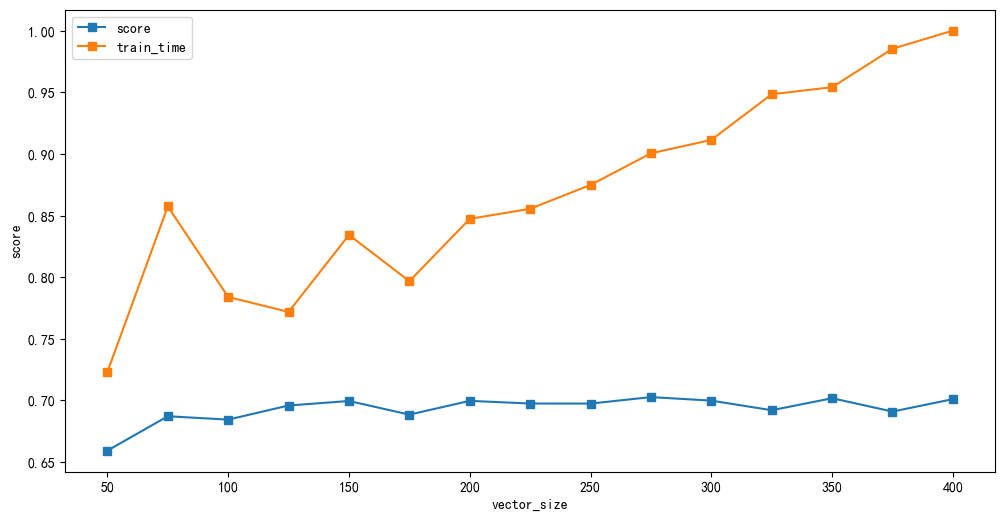

In [17]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(word2vec_result['vector_size'], word2vec_result['score'], marker='s', label = 'score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
plt.plot(word2vec_result['vector_size'], (word2vec_result['train_time'])/(word2vec_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('vector_size')
plt.ylabel('score')
plt.legend()

## 2.2 window 对模型的影响

In [28]:
from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 275
    min_count = 10
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for window in tqdm(range(3, 25, 3), desc = 'window', colour='blue'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        train_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec', epoch, vector_size, window, min_count, train_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_org_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


window:  12%|█▎        | 1/8 [00:33<03:56, 33.75s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
15  word2vec       5          275       3         10   33.746392        332   

       score  
15  0.611899  


window:  25%|██▌       | 2/8 [01:09<03:28, 34.79s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
16  word2vec       5          275       6         10   35.515936        332   

       score  
16  0.653292  


window:  38%|███▊      | 3/8 [01:45<02:57, 35.45s/it]

...

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
20  word2vec       5          275      18         10   41.999442        332   

       score  
20  0.711811  


window:  75%|███████▌  | 6/8 [03:54<01:23, 41.74s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
21  word2vec       5          275      21         10     45.8902        332   

       score  
21  0.723551  


window: 100%|██████████| 8/8 [05:35<00:00, 41.94s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
22  word2vec       5          275      24         10   50.756719        332   

       score  
22  0.722414  


In [40]:
window_result = exec_result.tail(8)
window_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
15,word2vec,5,275,3,10,33.746392,332,0.611899
16,word2vec,5,275,6,10,35.515936,332,0.653292
17,word2vec,5,275,9,10,36.232363,332,0.683754
18,word2vec,5,275,12,10,37.624132,332,0.699277
19,word2vec,5,275,15,10,39.483079,332,0.705806
20,word2vec,5,275,18,10,41.999442,332,0.711811
21,word2vec,5,275,21,10,45.890200,332,0.723551
22,word2vec,5,275,24,10,50.756719,332,0.722414


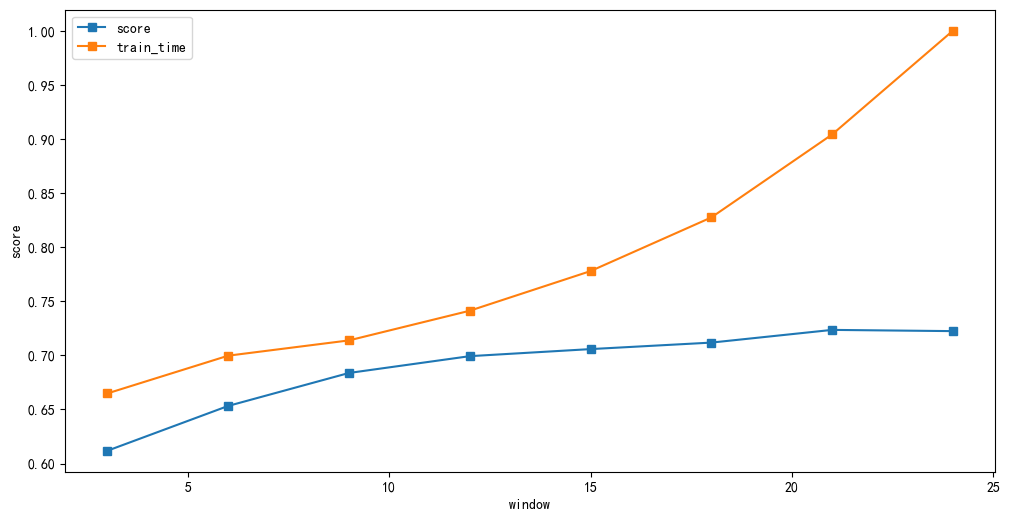

In [41]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(window_result['window'], window_result['score'], marker='s', label = 'score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
plt.plot(window_result['window'], (window_result['train_time'])/(window_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('window')
plt.ylabel('score')
plt.legend()

## 2.3 min_count 对模型的影响

In [43]:
from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 275
    window = 21
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for min_count in tqdm(range(5, 41, 5), desc = 'min_count', colour='green'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        train_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec', epoch, vector_size, window, min_count, train_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_org_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


min_count:  12%|█▎        | 1/8 [00:43<05:01, 43.02s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
23  word2vec       5          275      21          5   43.016542        333   

       score  
23  0.697305  


min_count:  25%|██▌       | 2/8 [01:28<04:27, 44.52s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
23  word2vec       5          275      21          5   43.016542        333   

       score  
23  0.697305  


min_count:  38%|███▊      | 3/8 [02:14<03:44, 44.98s/it]

...

min_count:  75%|███████▌  | 6/8 [04:32<01:31, 45.88s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
27  word2vec       5          275      21         30   45.195674        310   

      score  
27  0.72565  


min_count:  88%|████████▊ | 7/8 [05:18<00:45, 45.66s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
28  word2vec       5          275      21         35   45.207507        305   

     score  
28  0.7263  
       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
29  word2vec       5          275      21         40   44.919214        298   

       score  
29  0.737806  


min_count: 100%|██████████| 8/8 [06:05<00:00, 45.63s/it]


In [47]:
min_count_result = exec_result.tail(8).sort_values(by=['min_count'])
min_count_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
23,word2vec,5,275,21,5,43.016542,333,0.697305
22,word2vec,5,275,24,10,50.756719,332,0.722414
24,word2vec,5,275,21,15,45.516712,328,0.707019
25,word2vec,5,275,21,20,45.560777,322,0.716843
26,word2vec,5,275,21,25,45.214990,315,0.735552
27,word2vec,5,275,21,30,45.195674,310,0.725650
28,word2vec,5,275,21,35,45.207507,305,0.726300
29,word2vec,5,275,21,40,44.919214,298,0.737806


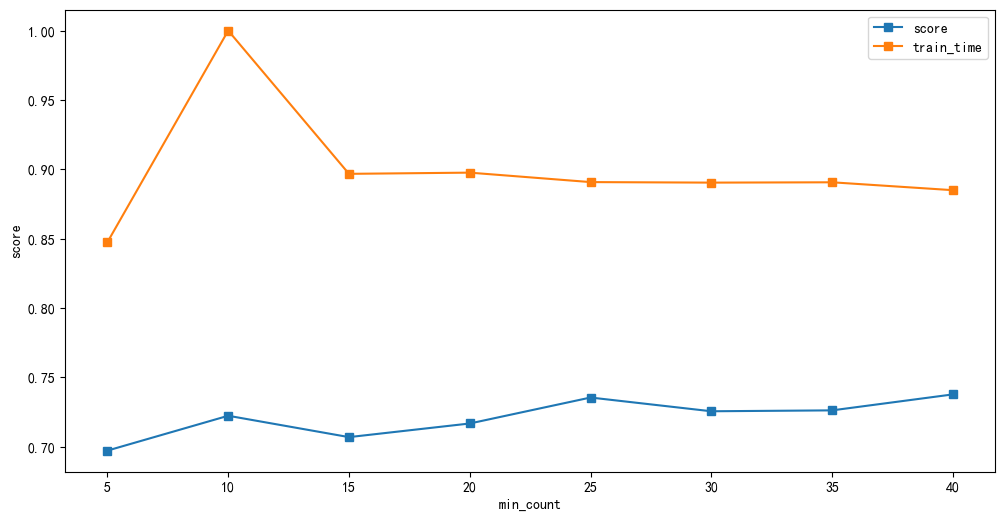

In [48]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(min_count_result['min_count'], min_count_result['score'], marker='s', label = 'score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
plt.plot(min_count_result['min_count'], (min_count_result['train_time'])/(min_count_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('min_count')
plt.ylabel('score')
plt.legend()

## 2.4 epochs 对模型的影响

In [49]:
from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 275
    window = 21
    min_count = 40
    model_workers = multiprocessing.cpu_count()
    for epoch in tqdm(range(5, 26, 5), desc = 'epochs', colour='yellow'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        train_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec', epoch, vector_size, window, min_count, train_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_org_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


epochs:  20%|██        | 1/5 [00:40<02:42, 40.71s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
29  word2vec       5          275      21         40   44.919214        298   

       score  
29  0.737806  
       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
30  word2vec      10          275      21         40   86.341171        298   

      score  
30  0.74396  


epochs:  60%|██████    | 3/5 [04:17<03:12, 96.06s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
31  word2vec      15          275      21         40  128.411176        298   

       score  
31  0.742049  


epochs:  80%|████████  | 4/5 [07:09<02:06, 126.09s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
32  word2vec      20          275      21         40  172.115214        298   

       score  
32  0.742799  


epochs: 100%|██████████| 5/5 [10:43<00:00, 128.62s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
33  word2vec      25          275      21         40    213.2654        298   

       score  
33  0.736613  


In [50]:
epoch_result = exec_result.tail(5).sort_values(by=['epochs'])
epoch_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
29,word2vec,5,275,21,40,44.919214,298,0.737806
30,word2vec,10,275,21,40,86.341171,298,0.743960
31,word2vec,15,275,21,40,128.411176,298,0.742049
32,word2vec,20,275,21,40,172.115214,298,0.742799
33,word2vec,25,275,21,40,213.265400,298,0.736613


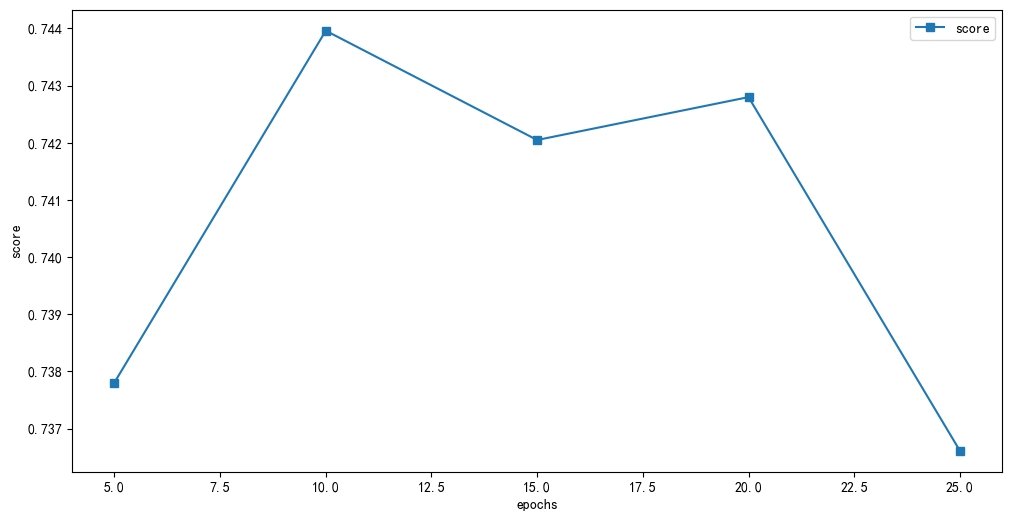

In [53]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(epoch_result['epochs'], epoch_result['score'], marker='s', label = 'score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
# plt.plot(epoch_result['epochs'], (epoch_result['train_time'])/(epoch_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('epochs')
plt.ylabel('score')
plt.legend()

## 三、更改模型

In [6]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'vector_size', 'window', 'min_count', 'train_time', 'vocab_len', 'score'])

### 3.1 skip-gram

#### 3.1.1 vector_size 

In [7]:

from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    window = 10
    min_count = 10
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for vector_size in tqdm(range(50, 401, 25), desc = 'vector_size', colour='red'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers,
                                        sg=1)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        training_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        exec_result.loc[exec_result.shape[0]] = ['word2vec_skip-gram', epoch, vector_size, window, min_count, training_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result.query("model == 'word2vec_skip-gram'")['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_skip-gram_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


vector_size:   0%|          | 0/15 [00:00<?, ?it/s]

                model  epochs  vector_size  window  min_count  train_time  \
0  word2vec_skip-gram       5           50      10         10   73.190574   

   vocab_len     score  
0        332  0.680381  


vector_size:   7%|▋         | 1/15 [01:14<17:18, 74.16s/it]

                model  epochs  vector_size  window  min_count  train_time  \
1  word2vec_skip-gram       5           75      10         10   80.535243   

   vocab_len     score  
1        332  0.683643  


vector_size:  13%|█▎        | 2/15 [02:36<17:03, 78.71s/it]

...

                 model  epochs  vector_size  window  min_count  train_time  \
11  word2vec_skip-gram       5          325      10         10   153.96034   

    vocab_len     score  
11        332  0.716738  


vector_size:  87%|████████▋ | 13/15 [25:26<04:48, 144.16s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
12  word2vec_skip-gram       5          350      10         10  161.410483   

    vocab_len     score  
12        332  0.709296  
                 model  epochs  vector_size  window  min_count  train_time  \
13  word2vec_skip-gram       5          375      10         10  174.250793   

    vocab_len     score  
13        332  0.719967  


vector_size: 100%|██████████| 15/15 [31:37<00:00, 126.51s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
14  word2vec_skip-gram       5          400      10         10  190.256181   

    vocab_len     score  
14        332  0.718401  


In [98]:
cbow_result =  exec_result.iloc[range(0,15),:]
skip_gram_result = exec_result.iloc[range(34,49),:]
skip_gram_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
34,word2vec_skip-gram,5,50,10,10,73.190574,332,0.680381
35,word2vec_skip-gram,5,75,10,10,80.535243,332,0.683643
36,word2vec_skip-gram,5,100,10,10,83.850510,332,0.696456
37,word2vec_skip-gram,5,125,10,10,96.139153,332,0.698634
38,word2vec_skip-gram,5,150,10,10,101.701529,332,0.714572
39,word2vec_skip-gram,5,175,10,10,110.521655,332,0.711118
40,word2vec_skip-gram,5,200,10,10,120.351117,332,0.714617
41,word2vec_skip-gram,5,225,10,10,122.254940,332,0.719049
42,word2vec_skip-gram,5,250,10,10,126.796506,332,0.706260
43,word2vec_skip-gram,5,275,10,10,139.913002,332,0.712258


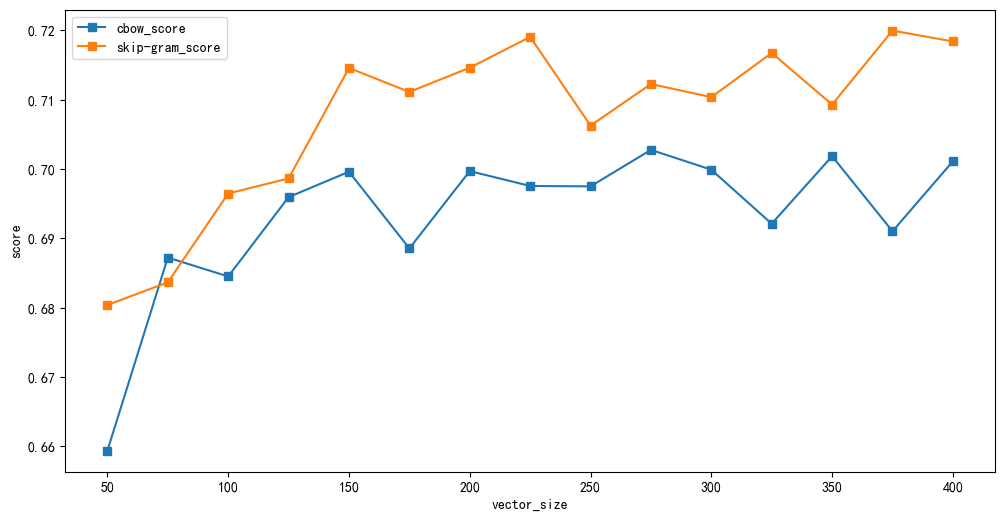

In [141]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(cbow_result['vector_size'], cbow_result['score'], marker='s', label = 'cbow_score')
plt.plot(skip_gram_result['vector_size'], skip_gram_result['score'], marker='s', label = 'skip-gram_score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
# plt.plot(cbow_result['vector_size'], (cbow_result['train_time'])/(cbow_result['train_time'].max()), marker='s', label = 'cbow_train_time')
# plt.plot(skip_gram_result['vector_size'], (skip_gram_result['train_time'])/(skip_gram_result['train_time'].max()), marker='s', label = 'skip_gram_train_time')
plt.xlabel('vector_size')
plt.ylabel('score')
plt.legend()

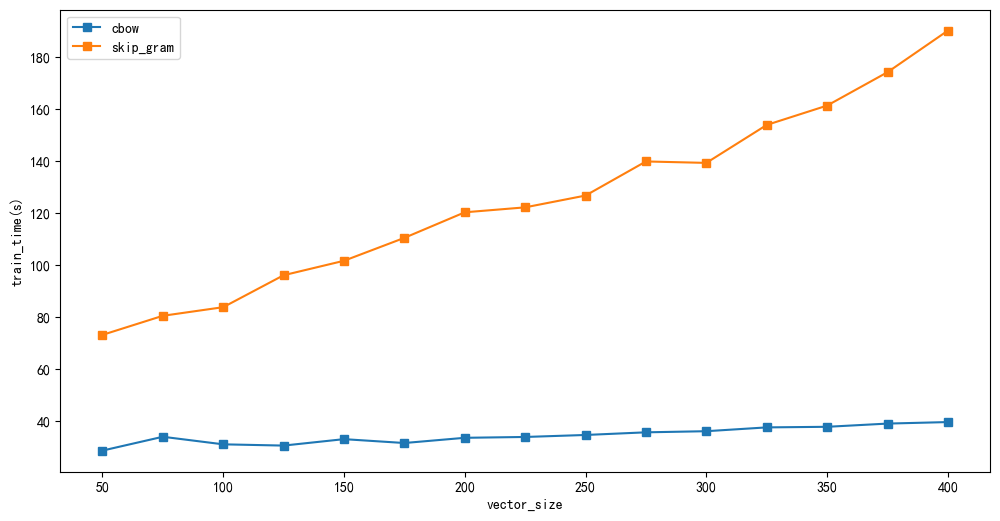

In [157]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
plt.plot(cbow_result['vector_size'], cbow_result['train_time'], marker='s', label = 'cbow')
plt.plot(skip_gram_result['vector_size'], skip_gram_result['train_time'], marker='s', label = 'skip_gram')
plt.xlabel('vector_size')
plt.ylabel('train_time(s)')
plt.legend()

#### 3.1.2 window

In [56]:

from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 225
    min_count = 10
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for window in tqdm(range(3, 25, 3), desc = 'window', colour='blue'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers,
                                        sg=1)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        training_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec_skip-gram' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec_skip-gram', epoch, vector_size, window, min_count, training_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result.query("model == 'word2vec_skip-gram'")['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_skip-gram_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


window:  12%|█▎        | 1/8 [00:51<05:57, 51.11s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
15  word2vec_skip-gram       5          225       3         10    51.10146   

    vocab_len     score  
15        332  0.657541  


window:  25%|██▌       | 2/8 [02:12<06:53, 68.91s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
16  word2vec_skip-gram       5          225       6         10   81.360073   

    vocab_len     score  
16        332  0.693542  


window:  38%|███▊      | 3/8 [04:01<07:16, 87.28s/it]

...

                 model  epochs  vector_size  window  min_count  train_time  \
20  word2vec_skip-gram       5          225      18         10  199.265112   

    vocab_len    score  
20        332  0.71357  


window:  88%|████████▊ | 7/8 [16:18<02:58, 178.12s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
21  word2vec_skip-gram       5          225      21         10  228.295762   

    vocab_len     score  
21        332  0.709935  


window: 100%|██████████| 8/8 [20:39<00:00, 154.91s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
22  word2vec_skip-gram       5          225      24         10  260.566322   

    vocab_len     score  
22        332  0.710256  


In [109]:
cbow_window_result =  exec_result.iloc[range(15,23),:]
skip_gram_window_result = exec_result.iloc[range(49,57),:]
skip_gram_window_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
49,word2vec_skip-gram,5,225,3,10,51.101460,332,0.657541
50,word2vec_skip-gram,5,225,6,10,81.360073,332,0.693542
51,word2vec_skip-gram,5,225,9,10,109.139532,332,0.715211
52,word2vec_skip-gram,5,225,12,10,139.393348,332,0.715591
53,word2vec_skip-gram,5,225,15,10,170.064251,332,0.717493
54,word2vec_skip-gram,5,225,18,10,199.265112,332,0.713570
55,word2vec_skip-gram,5,225,21,10,228.295762,332,0.709935
56,word2vec_skip-gram,5,225,24,10,260.566322,332,0.710256


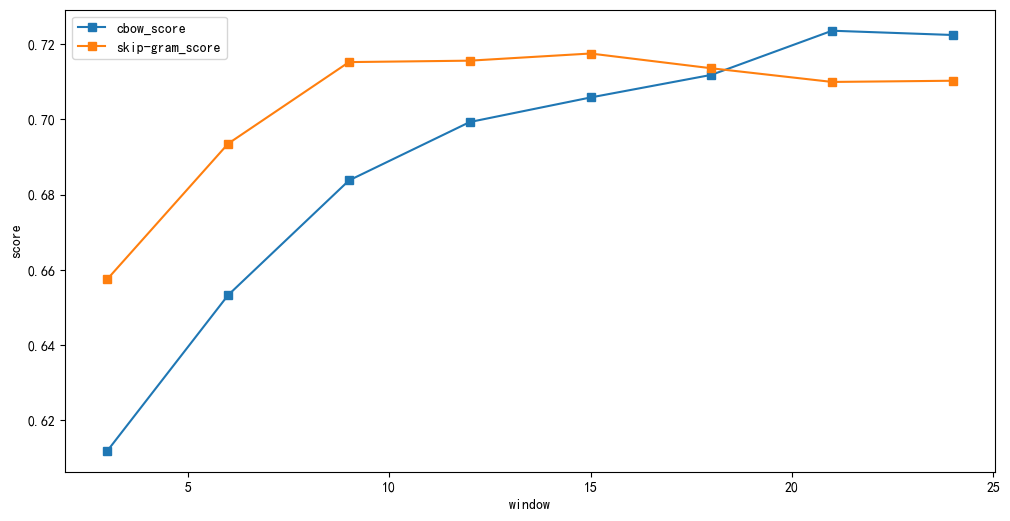

In [110]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(cbow_window_result['window'], cbow_window_result['score'], marker='s', label = 'cbow_score')
plt.plot(skip_gram_window_result['window'], skip_gram_window_result['score'], marker='s', label = 'skip-gram_score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
# plt.plot(window_result['window'], (window_result['train_time'])/(window_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('window')
plt.ylabel('score')
plt.legend()

#### 3.1.3 min_count

In [75]:

from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 275
    window = 15
    epoch = 5
    model_workers = multiprocessing.cpu_count()
    for min_count in tqdm(range(5, 41, 5), desc = 'min_count', colour='green'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers,
                                        sg=1)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        training_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec_skip-gram' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec_skip-gram', epoch, vector_size, window, min_count, training_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result.query("model == 'word2vec_skip-gram'")['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_skip-gram_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_skip-gram_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


min_count:  12%|█▎        | 1/8 [03:27<24:09, 207.09s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
57  word2vec_skip-gram       5          275      15          5   207.08754   

    vocab_len     score  
57        333  0.706746  
                 model  epochs  vector_size  window  min_count  train_time  \
58  word2vec_skip-gram       5          275      15         10  239.709668   

    vocab_len     score  
58        332  0.721153  


min_count:  25%|██▌       | 2/8 [07:31<22:54, 229.16s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
59  word2vec_skip-gram       5          275      15         15  240.870722   

    vocab_len     score  
59        328  0.729472  


min_count:  50%|█████     | 4/8 [15:51<16:15, 243.78s/it]

...

min_count:  75%|███████▌  | 6/8 [24:15<08:17, 248.69s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
62  word2vec_skip-gram       5          275      15         30  253.656131   

    vocab_len     score  
62        310  0.718649  


min_count:  88%|████████▊ | 7/8 [28:33<04:11, 251.57s/it]

                 model  epochs  vector_size  window  min_count  train_time  \
63  word2vec_skip-gram       5          275      15         35  257.489771   

    vocab_len     score  
63        305  0.718032  
                 model  epochs  vector_size  window  min_count  train_time  \
64  word2vec_skip-gram       5          275      15         40    254.3269   

    vocab_len     score  
64        298  0.736493  


min_count: 100%|██████████| 8/8 [32:50<00:00, 246.37s/it]


In [135]:
min_count_result = exec_result.iloc[np.append(list(range(23,30)), 9),:].sort_values(by=['min_count'])
min_count_result

cbow_min_count_result =   exec_result.iloc[range(23,30),:]
skip_gram_min_count_result = exec_result.iloc[range(57,65),:]
skip_gram_min_count_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
57,word2vec_skip-gram,5,275,15,5,207.087540,333,0.706746
58,word2vec_skip-gram,5,275,15,10,239.709668,332,0.721153
59,word2vec_skip-gram,5,275,15,15,240.870722,328,0.729472
60,word2vec_skip-gram,5,275,15,20,255.153633,322,0.705287
61,word2vec_skip-gram,5,275,15,25,250.274586,315,0.721314
62,word2vec_skip-gram,5,275,15,30,253.656131,310,0.718649
63,word2vec_skip-gram,5,275,15,35,257.489771,305,0.718032
64,word2vec_skip-gram,5,275,15,40,254.326900,298,0.736493


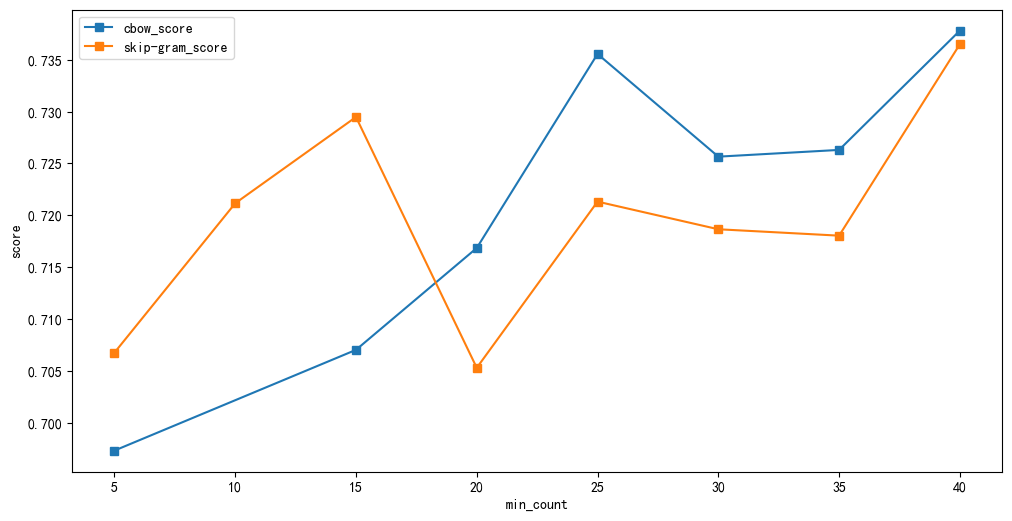

In [137]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(cbow_min_count_result['min_count'], cbow_min_count_result['score'], marker='s', label = 'cbow_score')
plt.plot(skip_gram_min_count_result['min_count'], skip_gram_min_count_result['score'], marker='s', label = 'skip-gram_score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
# plt.plot(min_count_result['min_count'], (min_count_result['train_time'])/(min_count_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('min_count')
plt.ylabel('score')
plt.legend()

#### 3.1.4 epochs

In [80]:
from tqdm import tqdm
from scipy.stats import spearmanr

logging.basicConfig(format='%(asctime)s : %(levelname)s : %(message)s',
                    level=logging.WARNING)

if __name__ == '__main__':

    data_path = 'text8'

    # loading dataset
    sents = word2vec.Text8Corpus('text8')


    vector_size = 275
    window = 15
    min_count = 40
    model_workers = multiprocessing.cpu_count()
    for epoch in tqdm(range(5, 26, 5), desc = 'epochs', colour='yellow'):
        # 开始时间
        t0 = time()
        # training word2vec
        model = gensim.models.Word2Vec(sents,   
                                        epochs=epoch,                                                    
                                        vector_size=vector_size, 
                                        window=window,
                                        min_count=min_count,
                                        workers=model_workers)               
        # testing on wordsim353
        sims = []
        ground_truth =[]
        with open('wordsim353/combined.csv') as f:
            for line in f.readlines()[1:]:
                l = line.strip().split(',')
                if l[0] in model.wv and l[1] in model.wv: # 过滤掉不在词表内的词 # shaw
                    sims.append(round(float(model.wv.similarity(l[0], l[1])), 2)) # 模型打分    
                    ground_truth.append(round(float(l[2]), 2)) # 人工真实评分     

        sims = np.array(sims)
        # 人工真实评分
        ground_truth = np.array(ground_truth)
        # 计算Spearman相关系数
        spcor = spearmanr(ground_truth, sims)[0]

        # 训练时间
        train_time = time() - t0

        # 保存训练结果
        # ['model', 'epoch', 'vector_size', 'window', 'min_count', 'train_time', 'score']
        if exec_result.query("model=='word2vec' & epochs=={} & vector_size=={} & window=={} & min_count=={}".format(epoch, vector_size, window, min_count)).shape[0] <= 0:
            exec_result.loc[exec_result.shape[0]] = ['word2vec', epoch, vector_size, window, min_count, train_time, len(sims), spcor]
        print(exec_result.loc[[exec_result.shape[0]-1]])

        # score效果更好时，保存模型及结果
        best_score = exec_result['score'].max()                    
        if float(best_score) <= float(spcor):
            # saving to file
            model.save('./output/word2vec_gensim_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count))
            model.wv.save_word2vec_format('./output/word2vec_org_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        './output/vocabulary_{}_{}_{}_{}'.format(epoch, vector_size, window, min_count),
                                        binary=False)
            np.save('./output/score_{}_{}_{}_{}.npy'.format(epoch, vector_size, window, min_count), np.array(sims))


epochs:  20%|██        | 1/5 [00:37<02:31, 37.90s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
65  word2vec       5          275      15         40   37.890566        298   

       score  
65  0.711517  


epochs:  40%|████      | 2/5 [01:53<03:00, 60.07s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
66  word2vec      10          275      15         40   75.588935        298   

      score  
66  0.73084  


epochs:  60%|██████    | 3/5 [04:04<03:04, 92.24s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
67  word2vec      15          275      15         40  130.514211        298   

       score  
67  0.727317  


epochs:  80%|████████  | 4/5 [06:57<02:04, 124.40s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
68  word2vec      20          275      15         40  173.687969        298   

      score  
68  0.73874  


epochs: 100%|██████████| 5/5 [10:30<00:00, 126.17s/it]

       model  epochs  vector_size  window  min_count  train_time  vocab_len  \
69  word2vec      25          275      15         40   213.11656        298   

       score  
69  0.724271  


In [153]:
cbow_epoch_result =  exec_result.iloc[range(29,34),:]
skip_gram_epoch_result = exec_result.iloc[range(65,70),:]
skip_gram_epoch_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
65,word2vec,5,275,15,40,37.890566,298,0.711517
66,word2vec,10,275,15,40,75.588935,298,0.730840
67,word2vec,15,275,15,40,130.514211,298,0.727317
68,word2vec,20,275,15,40,173.687969,298,0.738740
69,word2vec,25,275,15,40,213.116560,298,0.724271


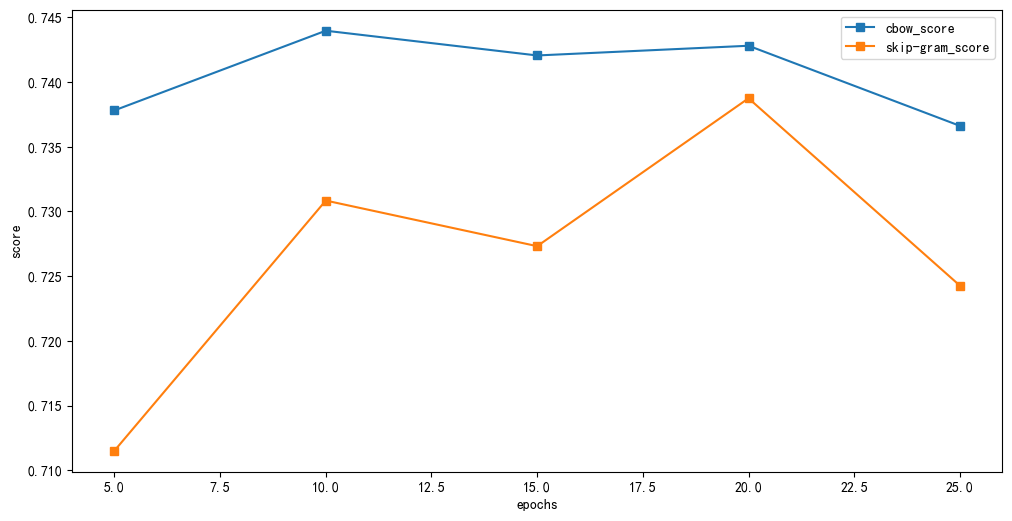

In [156]:
plt.figure(figsize=(12,6), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(cbow_epoch_result['epochs'], cbow_epoch_result['score'], marker='s', label = 'cbow_score')
plt.plot(skip_gram_epoch_result['epochs'], skip_gram_epoch_result['score'], marker='s', label = 'skip-gram_score')
# 为方便在一个图上比较趋势，训练时间作了“max标准化”处理
# plt.plot(epoch_result['epochs'], (epoch_result['train_time'])/(epoch_result['train_time'].max()), marker='s', label = 'train_time')
plt.xlabel('epochs')
plt.ylabel('score')
plt.legend()

## 四、实验模型最优参数和结果

In [139]:
exec_result

,model,epochs,vector_size,window,min_count,train_time,vocab_len,score
0,word2vec,5,50,10,10,28.672798,332,0.659362
1,word2vec,5,75,10,10,33.993545,332,0.687215
2,word2vec,5,100,10,10,31.082063,332,0.684491
3,word2vec,5,125,10,10,30.602140,332,0.695937
4,word2vec,5,150,10,10,33.077674,332,0.699601
...,...,...,...,...,...,...,...,...
65,word2vec,5,275,15,40,37.890566,298,0.711517
66,word2vec,10,275,15,40,75.588935,298,0.730840
67,word2vec,15,275,15,40,130.514211,298,0.727317
68,word2vec,20,275,15,40,173.687969,298,0.738740


In [162]:
best_index = exec_result['score'].idxmax()  
best_result = exec_result.iloc[best_index]
best_result

model           word2vec
epochs                10
vector_size          275
window                21
min_count             40
train_time     86.341171
vocab_len            298
score            0.74396
Name: 30, dtype: object